# Build Forcing Validation - Humidity
- Tony Grove

In [1]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from buildforcing.datasets import PNNLSnotel
import os

In [2]:
# Run parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20151001'
end_date = '20161001'
buildforcing_version = 'v0.4.0'
#environment = '/home/chriscox/Data/'
environment = 'C:/Users/clmbn/NMT_PhD/data/' # Windows

In [ ]:
# Create a data extraction function for forcing data
def get_forcing_values(forcing_file, variable, start_date, end_date) -> pd.DataFrame:
    """
    Extract forcing values from a NetCDF file for a given variable and date range.
    
    Parameters:
        forcing_file (str): Path to the NetCDF file.
        variable (str): Variable name to extract.
        start_date (str): Start date in 'YYYYMMDD' format.
        end_date (str): End date in 'YYYYMMDD' format.

    Returns:
        pd.DataFrame: DataFrame containing the extracted values.
    """
    ds = xr.open_dataset(forcing_file)
    subset = ds[variable].isel(latitude=0, longitude=0)
    df: pd.DataFrame = subset.to_dataframe()
    ds.close() # Seems to help when running in Jupyter Notebook

    df = df.loc[start_date:end_date]
    
    return df

### Load datasets

In [3]:
# Load the forcing and NLDAS datasets
sitename = site.replace(' ', '').lower()
forcing = xr.open_dataset(os.path.join(environment, 'forcing', f'{sitename}_{start_date}_{end_date}_{buildforcing_version}.nc'))

In [ ]:
nldas = xr.open_dataset(os.path.join(environment, 'nldas', f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [ ]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [4]:
forcing_Qair = forcing['Qair'].isel(latitude=0, longitude=0).to_dataframe()

# Localize the forcing data and convert to America/Denver timezone
forcing_Qair.index = forcing_Qair.index.tz_localize('UTC').tz_convert('America/Denver')

### GAMUT Data
In order to compare specific humidity to the GAMUT station, I use the HC2S3 sensor at the station. If I remember correctly, this sensor had an issue where it was getting solar heating, so readings my not be as accurate as they should be. The station measures % relative humidity with respect to vapor pressure. Barry and Chorley show that specific humidity $q$ relative to saturation $q/q_s$ should be less than relative humidity, so I will use that as a first point of analysis.

Per a source online that looked legit:
$$q_s \approx \frac{\epsilon e_s}{P}$$

Where $\epsilon$ is the ratio of wet/dry gas constants (0.622) So I need pressure and temperature (using ST110 thermister) to calculate saturation vapor pressure. I will use the following equation for saturation vapor pressure (wikipedia):
$$e_s = 6.11 \exp\left(\frac{17.27 T}{T + 237.3}\right)$$

Where $T$ is in Celsius and $e_s$ is in kPa.

In [5]:
gamut_st110 = pd.read_csv(
    os.path.join(environment, 'gamut/tonygrovers', f'LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv'),
    skiprows=56
    )

# Create datetime index from LocalDateTime
gamut_st110.index = pd.DatetimeIndex(
    pd.to_datetime(gamut_st110['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
)

# I only need 2015-2016 data
gamut_st110 = gamut_st110.loc['2015-10-01':'2016-10-01']


In [6]:
gamut_hc2s3 = pd.read_csv(
    os.path.join(environment, 'gamut/tonygrovers', f'LR_TG_C_RH_HC2S3_SourceID_1_QC_1.csv'),
    skiprows=55
    )

# Create datetime index from LocalDateTime
gamut_hc2s3.index = pd.DatetimeIndex(
    pd.to_datetime(gamut_hc2s3['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
)
# I only need 2015-2016 data
gamut_hc2s3 = gamut_hc2s3.loc['2015-10-01':'2016-10-01']

In [7]:
# Load the pressure data from LR_TG_C_BP_Avg_SourceID_1_QC_1.csv
gamut_bp = pd.read_csv(
    os.path.join(environment, 'gamut/tonygrovers', f'LR_TG_C_BP_Avg_SourceID_1_QC_1.csv'),
    skiprows=55
    )

# Create datetime index from LocalDateTime
gamut_bp.index = pd.DatetimeIndex(
    pd.to_datetime(gamut_bp['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
)
# I only need 2015-2016 data
gamut_bp = gamut_bp.loc['2015-10-01':'2016-10-01']

In [8]:
# Combine the data into a single DataFrame
gamut_data = pd.merge(gamut_st110['AirTemp_ST110_Avg'],gamut_hc2s3['RH_HC2S3'], left_index=True, right_index=True)
gamut_data = gamut_data.join(gamut_bp['BP_Avg'], how='left')

# Change all -9999 to NaN
gamut_data = gamut_data.replace(-9999, np.nan)

# Localize the data to the timezone of the site. Note the gamut data has a constant UTC offset of -7 hours
gamut_data.index = gamut_data.index - pd.Timedelta(hours=7)
gamut_data.index = gamut_data.index.tz_localize('UTC').tz_convert('America/Denver')

### Try using MetPy


In [9]:
from metpy.calc import relative_humidity_from_specific_humidity
from metpy.units import units

In [10]:
# Get temperature and pressure from the gamut data
forcing_Qair = forcing_Qair.join(gamut_data['BP_Avg'], how='left')
forcing_Qair = forcing_Qair.join(gamut_data['AirTemp_ST110_Avg'], how='left')

In [11]:
qair = relative_humidity_from_specific_humidity(
    temperature=forcing_Qair['AirTemp_ST110_Avg'].values * units.degC,
    pressure=forcing_Qair['BP_Avg'].values * units.kPa,
    specific_humidity=forcing_Qair['Qair'].values
).to('percent')

forcing_Qair['RH'] = qair.magnitude

### Calculate saturated specific humidity
When I did this manually, I somehow missed a factor of 10, otherwise the calculations below match metpy

In [ ]:
gamut_data['es'] = 6.11 * np.exp((17.27 * gamut_data['AirTemp_ST110_Avg']) / (gamut_data['AirTemp_ST110_Avg'] + 237.3))

In [ ]:
gamut_data['qs'] = (0.622 * gamut_data['es']) / gamut_data['BP_Avg'] 

In [ ]:
forcing_Qair = forcing_Qair.join(gamut_data['qs'], how='left')

In [ ]:
forcing_Qair['RH'] = (forcing_Qair['Qair'] / forcing_Qair['qs'])*100

## Comparisons

<Axes: xlabel='LocalDateTime'>

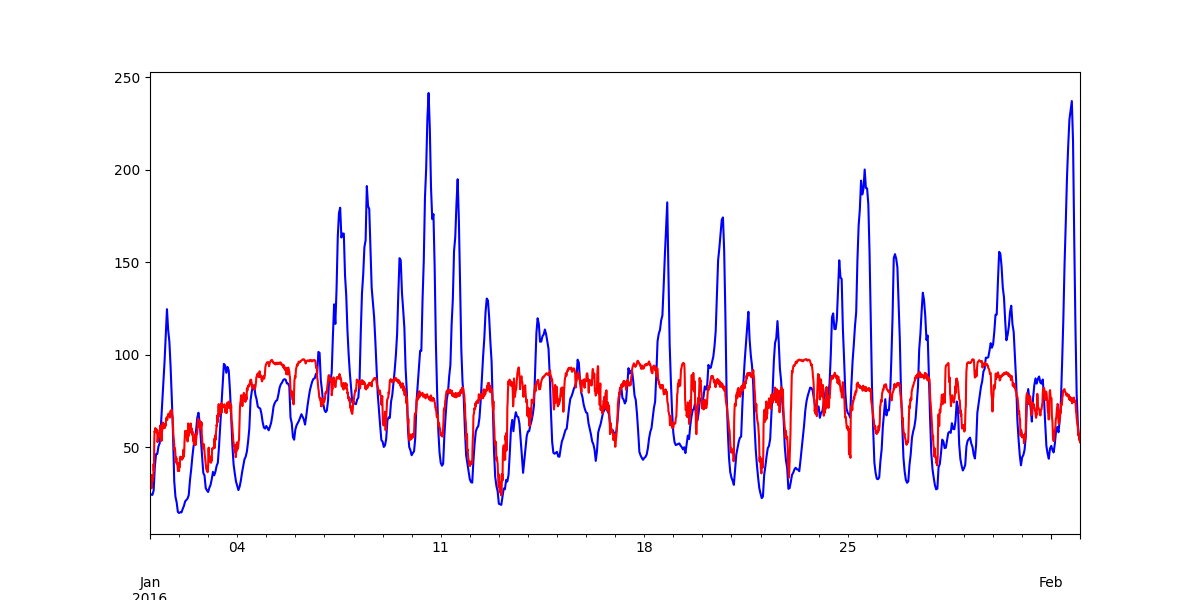

In [12]:
# Plot Tair and compare to ST110 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Qair.loc['20160101':'20160201','RH'].plot(ax=ax, label='Qair_RH', color='blue')
gamut_data.loc['20160101':'20160201','RH_HC2S3'].plot(ax=ax, label='GAMUT_RH', color='red')

In [ ]:
# Load Tair V0 for comparison
sitename = site.replace(' ', '').lower()
datapath_v0 = os.path.join(environment,'forcing',f'{sitename}_{start_date}_{end_date}_v0.1.0.nc')
forcing_Tair_v0 = get_forcing_values(datapath_v0, 'Tair', start_date, end_date)
forcing_Tair_v0['Tair_C'] = forcing_Tair_v0['Tair'] - 273.15
forcing_Tair_v0.index = forcing_Tair_v0.index.tz_localize('UTC').tz_convert('America/Denver')

In [ ]:
# Compare Tair V0 to V1
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair V1 (C)', color='r', linestyle='-')
forcing_Tair_v0['Tair_C'].plot(ax=ax, label='Forcing Tair V0 (C)', color='r', linestyle='--')
gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', color='b', linestyle='-')


#